# 01 · Physics core — orthogonal cutting, single shear plane
**ME361 digital machining twin** · notation exactly as in Lecture-2 slides (Pz, Pxy, Ps, PN, F, N, R, β, η, γ₀, μ=tanη).

Pipeline: inputs (Vc, t, τs, σy) → friction angle η=atan μ → shear angle β (model) → Ps=τs·w·t/sinβ → R=Ps/cos(β+η−γ₀) → Pz=R cos(η−γ₀), Pxy=R sin(η−γ₀).

> ⚠️ The slide model is **rate-independent**: Vc does not appear in Pz/Pxy. Vc only drives the animation kinematics until a correction factor (`c_rate`, `m_mu`) is calibrated from data. That is expected, and is exactly what the validation step is for.
> ⚠️ The model also needs w (tube wall thickness), γ₀ and μ. These are *fixed tool/interface constants*, not live inputs. μ is the first calibration knob.

In [1]:
import sys; sys.path.insert(0,'.')
import numpy as np, matplotlib.pyplot as plt
from orthocut import *

## 1. Unit tests against the slide numericals

In [2]:
# Numerical 1: gamma0=0, Pz=950, Pxy=475, w=2.5, t=0.25, chip thickness 0.75 -> mu=0.5, tau_s ~ 379-380 MPa
mu = mu_from_forces(950, 475, 0); beta = beta_from_chip_ratio(0.25/0.75, 0)
tau = tau_s_from_forces(950, 475, beta, 2.5, 0.25)
print(f'mu={mu:.3f}  beta={beta:.2f} deg  tau_s={tau:.1f} MPa'); assert abs(mu-0.5)<1e-9 and abs(tau-379.4)/379.4<0.01

# Numerical 2: Vc=200, w=2, t=0.2, mu=0.5, tau_s=400, gamma0=10 deg (gamma0 inferred: reproduces all three slide betas)
for model, beta_slide in [('ernst_merchant',36.7), ('merchant_C',26.7), ('lee_shaffer',28.43)]:
    r = solve(Material('slide',400), Tool(10,0.5), Cut(200,0.2,2), Corrections(shear_model=model, C_merchant=70))
    print(f'{model:15s} beta={r.beta_deg:6.2f} (slide {beta_slide})  Pz={r.Pz:6.1f}  Pxy={r.Pxy:6.1f}'); assert abs(r.beta_deg-beta_slide)<0.05
print('\nSlide handwritten forces: E-M 480/125, C=70: 489.6/144.9, Lee-Shaffer 481/160.6 -> our values differ 4-12% (see handoff, Open Issue 1)')

mu=0.500  beta=18.43 deg  tau_s=380.0 MPa
ernst_merchant  beta= 36.72 (slide 36.7)  Pz= 429.0  Pxy= 127.6
merchant_C      beta= 26.72 (slide 26.7)  Pz= 468.6  Pxy= 139.4
lee_shaffer     beta= 28.43 (slide 28.43)  Pz= 455.5  Pxy= 135.5

Slide handwritten forces: E-M 480/125, C=70: 489.6/144.9, Lee-Shaffer 481/160.6 -> our values differ 4-12% (see handoff, Open Issue 1)


## 2. Internal consistency (force circle closes)

In [3]:
r = solve(Material('Al 7050',303,505), Tool(13,0.5), Cut(200,0.10,2.0))
g=np.radians(13); print('R check   :', np.hypot(r.Pz,r.Pxy), r.R)
print('F/N = mu   :', r.F/r.N)
print('Ps (slide) :', r.Ps, ' vs tau*w*t/sin(beta)=', 303*2*0.10/np.sin(np.radians(r.beta_deg)))
print(r)

R check   : 158.338067004077 158.338067004077
F/N = mu   : 0.4999999999999999
Ps (slide) : 97.95553511898689  vs tau*w*t/sin(beta)= 97.95553511898686
Result(beta_deg=np.float64(38.217474411461005), eta_deg=np.float64(26.56505117707799), mu_eff=0.5, tau_eff=np.float64(303.0), Ps=np.float64(97.95553511898689), PN=np.float64(124.40119212507777), F=np.float64(70.81093624940652), N=np.float64(141.62187249881308), R=158.338067004077, Pz=np.float64(153.92110785005502), Pxy=np.float64(37.13806700407698), Px=np.float64(0.0), Py=np.float64(37.13806700407698), r=np.float64(0.6838178272743161), t_chip=np.float64(0.14623777855952946), V_chip=np.float64(2.2793927575810535), V_shear=np.float64(3.5900413777392437), gamma0_deg=13)


## 3. Parameter sweeps (what the live twin will show)

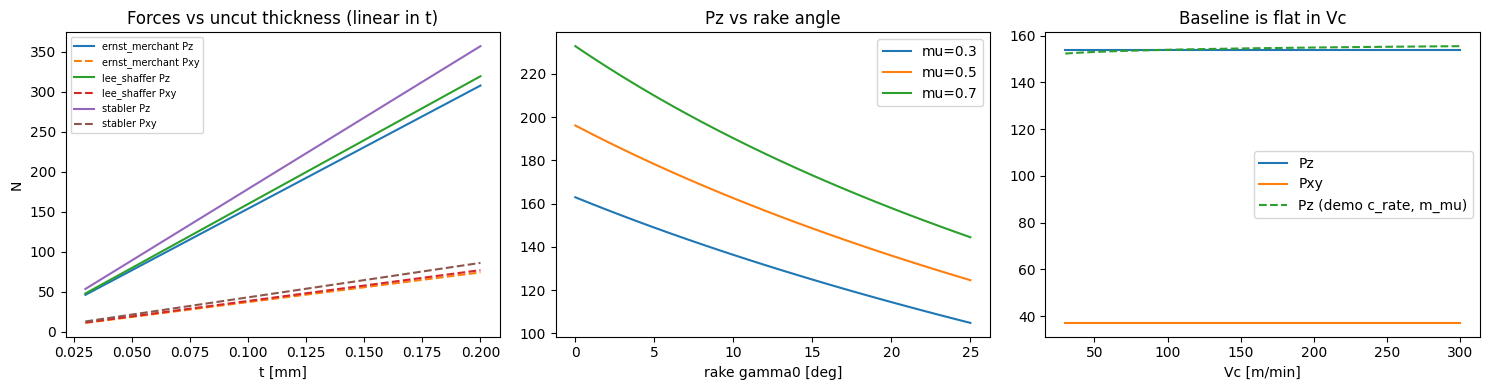

In [4]:
ts=np.linspace(0.03,0.2,30); fig,ax=plt.subplots(1,3,figsize=(15,4))
for m in ['ernst_merchant','lee_shaffer','stabler']:
    R=[solve(Material('Al',303),Tool(13,0.5),Cut(150,t,2),Corrections(shear_model=m)) for t in ts]
    ax[0].plot(ts,[x.Pz for x in R],label=m+' Pz'); ax[0].plot(ts,[x.Pxy for x in R],'--',label=m+' Pxy')
ax[0].set_xlabel('t [mm]'); ax[0].set_ylabel('N'); ax[0].legend(fontsize=7); ax[0].set_title('Forces vs uncut thickness (linear in t)')
for mu in [0.3,0.5,0.7]:
    gs=np.linspace(0,25,26); R=[solve(Material('Al',303),Tool(g,mu),Cut(150,0.1,2)) for g in gs]
    ax[1].plot(gs,[x.Pz for x in R],label=f'mu={mu}')
ax[1].set_xlabel('rake gamma0 [deg]'); ax[1].set_title('Pz vs rake angle'); ax[1].legend()
Vs=np.linspace(30,300,20); R=[solve(Material('Al',303),Tool(13,0.5),Cut(V,0.1,2)) for V in Vs]
ax[2].plot(Vs,[x.Pz for x in R],label='Pz'); ax[2].plot(Vs,[x.Pxy for x in R],label='Pxy')
R=[solve(Material('Al',303),Tool(13,0.5),Cut(V,0.1,2),Corrections(c_rate=0.05,m_mu=0.1)) for V in Vs]
ax[2].plot(Vs,[x.Pz for x in R],'--',label='Pz (demo c_rate, m_mu)'); ax[2].set_xlabel('Vc [m/min]'); ax[2].set_title('Baseline is flat in Vc'); ax[2].legend()
plt.tight_layout(); plt.show()

## 4. Task list for this notebook (Member A)
- [ ] Confirm γ₀ of the lab insert/holder (lab sheet lists 13° and also αn=45° — inconsistent) and fix `Tool.gamma0_deg`.
- [ ] Re-derive kinematic relations (chip ratio r, Vchip, Vshear) against the slides; cite slide numbers in the docstring.
- [ ] Decide default shear-angle model after the first data comparison (notebook 03).